In [1]:
import os, glob, sys, numbers
sys.path.append("../")

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.interpolate import griddata, RegularGridInterpolator
import pygeode as pyg
from jfunctions import *
import scipy.interpolate as intp
from scipy.ndimage import uniform_filter1d
import xarray as xr
from wavenumber_frequency_functions import *
from matplotlib import colors
from tropopause import *

%matplotlib widget

save = False
save_loc = '/home/cwp29/tmp/mpas/crf_on/'

In [2]:
##### config_microp_re on/off test #####
#root_dir = '/store/atmos-adk33/cwp29/mpas-a/data/trop_ref/'
#data_locs = ['spinup/latlon_05deg.nc', 'microp_re_test/latlon_regridded_05deg.nc']
#sim_names = ['default', 'microp_re']

##### CRF on/off test #####
#root_dir = '/store/atmos-adk33/cwp29/mpas-a/data/qu_120km/'
#data_locs = ['control', 'crf_test']
#latlon_file = ['', 'latlon_spinup.nc']
#sim_names = ['crf on', 'crf off']

root_dir = '/store/atmos-adk33/cwp29/mpas-a/data/trop_ref/crf_on/'
data_locs = ['control', 'u_nudge', 'T_nudge']
latlon_file = ['latlon.2000-*.nc', 'latlon.2000-*.nc', 'latlon.2000-*.nc']
sim_names = ['control', 'nudged u', 'nudged T']

cols = ['k', 'b', 'r']

# Use final 'ndays' of data
ndays = 10
dt = 6

time_format = 'time' #or 'int'

In [3]:
def load_latlon_dataset(
    data_dir,
    latlon_pattern="latlon.2000-*.nc",
    diag_file="latlon_diag.nc",
    hist_file="latlon_hist.nc",
    cldfrac_file="cldfrac.nc",
    time_format="int",
    dt=6,
    ndays=None,
    chunks=None,
):
    diag_path = os.path.join(data_dir, diag_file)
    hist_path = os.path.join(data_dir, hist_file)
    cldfrac_path = os.path.join(data_dir, cldfrac_file)
    latlon_files = sorted(glob.glob(os.path.join(data_dir, latlon_pattern)))

    # Open lazily; rechunk later if needed
    if os.path.exists(diag_path) and os.path.exists(hist_path):
        dsd = xr.open_dataset(diag_path, chunks={})
        dsh = xr.open_dataset(hist_path, chunks={})

        if time_format == "int":
            dsd = dsd.isel(Time=slice(0, None, 2))
        else:
            dsd = dsd.sel(Time=dsh.Time)

        ds = xr.merge([dsh, dsd], join="exact", compat="override")

    elif latlon_files:
        ds = xr.open_mfdataset(latlon_files, combine="by_coords", chunks={}, data_vars="minimal", coords="minimal")
        print(ds)

    else:
        raise FileNotFoundError(
            f"Could not find either {latlon_pattern} or both {diag_file} and {hist_file} in {data_dir}"
        )

    # Trim early, before adding extra variables
    if ndays is not None:
        if time_format == "int":
            ntime = ndays * int(24 / dt)
            ds = ds.isel(Time=slice(-ntime, None))
        else:
            t_end = pd.to_datetime(ds.Time.max().item())
            t_start = t_end - pd.Timedelta(days=ndays)
            ds = ds.sel(Time=slice(t_start, t_end))

    # Add cldfrac only for matching times, without a full merge
    if os.path.exists(cldfrac_path):
        ds_cld = xr.open_dataset(cldfrac_path, chunks={})

        if "cldfrac" in ds_cld:
            # align cldfrac to ds.Time; missing times become NaN
            cldfrac = ds_cld["cldfrac"].reindex(Time=ds.Time)
            ds = ds.assign(cldfrac=cldfrac)

    # Rechunk only at the end
    if chunks is not None:
        ds = ds.chunk(chunks)

    return ds

In [4]:
dss = []

pres = np.array([100, 200, 300, 500, 700, 1000, 2000, 3000, 5000, 7000, 10000, 15000, 20000, 25000, 30000, 40000, 50000, 60000, 70000, 85000, 92500, 100000], dtype=np.float64)
pres /= 100

needed_vars = [
    "rainnc", "i_rainnc", "rainc", "i_rainc", "precipw",
    "uzonal_isobaric", "umeridional_isobaric", "omg_isobaric",
    "rh_isobaric", "t_isobaric", "qv_isobaric", "theta",
    "uReconstructZonal", "cldfrac", "olrtoa", "zgrid", "pressure", "vorticity", "ke"
]

check_vars = ['t_isobaric']

for i, d in enumerate(data_locs):
    """
    if i == 0:
        dsd = xr.open_dataset(os.path.join(root_dir, 'control/latlon_diag.nc'), chunks={'Time': 4})
        dsh = xr.open_dataset(os.path.join(root_dir, 'control/latlon_hist.nc'), chunks={'Time': 4})
        #print(dsd)
        #print(dsh)
        
        # keep only times present in the 6h dataset
        if time_format == 'int':
            dsd_6h = dsd.isel(Time=slice(0, None, 2))
        else:
            dsd_6h = dsd.sel(Time=dsh.Time)
        
        # merge variables into one dataset
        ds = xr.merge([dsh, dsd_6h], join="exact") 
        
    else:
        ds = xr.open_dataset(os.path.join(root_dir, d), chunks={'Time': 4})

    # Dataset before time restriction
    print(ds.data_vars)

    if time_format == 'int':
        ds = ds.sel(Time=slice(-1-ndays*int(24/dt), -1))
    else:
        # Restrict time
        t_end = pd.to_datetime(ds.Time.max().item())
        t_start = t_end - pd.Timedelta(days=ndays)
        print(t_start, t_end)
        ds = ds.sel(Time=slice(t_start, t_end))
    """
    ds = load_latlon_dataset(
        os.path.join(root_dir, d),
        latlon_pattern=latlon_file[i],
        ndays=ndays,
        chunks={"Time": -1}
    )

    # Restrict variables
    keep = [v for v in needed_vars if v in ds.data_vars]
    ds = ds[keep]
    
    rename_map = {}
    if "nIsoLevelsU" in ds.dims:
        rename_map["nIsoLevelsU"] = "pres"
    if "nIsoLevelsT" in ds.dims:
        rename_map["nIsoLevelsT"] = "pres"
    if "nIsoLevelsZ" in ds.dims:
        rename_map["nIsoLevelsZ"] = "pres"
    if rename_map:
        ds = ds.rename(rename_map)

    # cheaper if data are exactly 6-hourly and aligned
    #ds = ds.coarsen(Time=4, boundary="trim").mean()

    ds = ds.assign_coords(pres=pres)
    
    print(ds)
    dss.append(ds)

if issubclass(ds.Time.values.dtype.type, numbers.Integral):
    time = ds.Time.values * dt/24.
else:
    time = ds.Time.values
print(time)

<xarray.Dataset> Size: 1TB
Dimensions:                 (latitude: 360, longitude: 720, nVertLevelsP1: 76,
                             nVertLevels: 75, Time: 839, nIsoLevelsT: 22,
                             nIsoLevelsZ: 22, nIsoLevelsU: 22)
Coordinates:
  * latitude                (latitude) float32 1kB -89.75 -89.25 ... 89.25 89.75
  * longitude               (longitude) float32 3kB -179.8 -179.2 ... 179.8
  * Time                    (Time) datetime64[ns] 7kB 2000-05-05T06:00:00 ......
Dimensions without coordinates: nVertLevelsP1, nVertLevels, nIsoLevelsT,
                                nIsoLevelsZ, nIsoLevelsU
Data variables: (12/49)
    zgrid                   (nVertLevelsP1, latitude, longitude) float32 79MB dask.array<chunksize=(76, 360, 720), meta=np.ndarray>
    zz                      (nVertLevels, latitude, longitude) float32 78MB dask.array<chunksize=(75, 360, 720), meta=np.ndarray>
    u                       (Time, nVertLevels, latitude, longitude) float32 65GB dask.arr

In [5]:
def lat_mean(da, lat_dim='latitude'):
    w = np.cos(np.deg2rad(da[lat_dim]))
    return da.weighted(w).mean(dim=lat_dim)

In [ ]:
# rainc, rainnc contain accumulated rainfall from simulation start to given timestep
fig, ax = plt.subplots(2, 1, figsize=(8, 4.5), constrained_layout=True)

for i, ds in enumerate(dss):
    precip = ds['rainnc'] + ds['i_rainnc']*100. + ds['rainc'] + ds['i_rainc']*100.
    precip_rate = np.gradient(lat_mean(precip.mean(dim='longitude')).values)
    
    precip_water = lat_mean(ds.precipw.mean(dim='longitude')).values

    ax[0].plot(time, precip_water, color=cols[i], label=sim_names[i])
    ax[1].plot(time, precip_rate, color=cols[i])

ax[0].set_ylim(18, 23)
ax[0].set_ylabel(r"Precipitable water (mm)")

ax[1].set_ylim(2, 4)
ax[1].set_ylabel(r"Rainfall rate (mm day$^{-1}$)")

ax[1].set_xlabel('Time (days)')

fig.legend(loc='outside lower center', ncol=4)

if save: save_fig(fig, save_loc+'comp_rain_stats.png', dpi=300)

[2.6943016e+01 1.0314936e+02 2.1620634e+02 3.5554413e+02 5.1677612e+02
 6.9721179e+02 8.9497144e+02 1.1086423e+03 1.3371121e+03 1.5794739e+03
 1.8349713e+03 2.1029585e+03 2.3828772e+03 2.6742385e+03 2.9766091e+03
 3.2896008e+03 3.6128643e+03 3.9460820e+03 4.2889658e+03 4.6412505e+03
 5.0026914e+03 5.3730625e+03 5.7521523e+03 6.1397646e+03 6.5357148e+03
 6.9398330e+03 7.3519570e+03 7.7719326e+03 8.1996162e+03 8.6348721e+03
 9.0775713e+03 9.5275889e+03 9.9848076e+03 1.0449117e+04 1.0920411e+04
 1.1398586e+04 1.1883543e+04 1.2375190e+04 1.2873439e+04 1.3378203e+04
 1.3889398e+04 1.4406945e+04 1.4930766e+04 1.5460786e+04 1.5996935e+04
 1.6539141e+04 1.7087336e+04 1.7641461e+04 1.8201453e+04 1.8767248e+04
 1.9338787e+04 1.9916012e+04 2.0498867e+04 2.1087301e+04 2.1681262e+04
 2.2280699e+04 2.2885562e+04 2.3495801e+04 2.4111365e+04 2.4732219e+04
 2.5358312e+04 2.5989598e+04 2.6626035e+04 2.7267594e+04 2.7914219e+04
 2.8565879e+04 2.9222531e+04 2.9884137e+04 3.0550668e+04 3.1222078e+04
 3.189

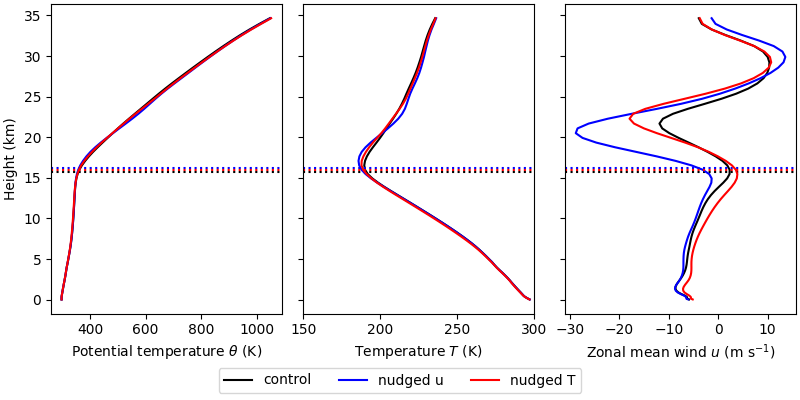

In [7]:
# Vertical profiles of tropical-mean potential temperature (theta) and zonal-mean wind (uReconstructZonal)

fig, ax = plt.subplots(1, 3, figsize=(8, 4), sharey=True, constrained_layout=True)

for i, ds in enumerate(dss):
    theta = ds.theta.sel(latitude=slice(-10, 10)).mean(dim=('Time', 'latitude', 'longitude'))
    pressure = ds.pressure.sel(latitude=slice(-10, 10)).mean(dim=('Time', 'latitude', 'longitude'))
    u = ds.uReconstructZonal.sel(latitude=slice(-10, 10)).mean(dim=('Time', 'latitude', 'longitude'))

    T = theta * (pressure / 100000.)**(287.0 / 1004.0)
    T_iso = ds.t_isobaric.sel(latitude=slice(-10, 10)).mean(dim=('Time', 'latitude', 'longitude'))
    
    zgrid = ds.zgrid.sel(latitude=slice(-10, 10)).mean(dim=('latitude', 'longitude'))
    z = 0.5 * (zgrid.isel(nVertLevelsP1=slice(0, -1)).values +
               zgrid.isel(nVertLevelsP1=slice(1, None)).values)

    print(z, pressure.values)
    ttp, ptp, ztp, _ = tropopause_profile(T.values, pressure.values, z)
    print(ttp, ptp, ztp)

    for a in ax:
        a.axhline(ztp/1000., color=cols[i], ls=':')
        
    ax[0].plot(theta.values, z/1000., color=cols[i], label=sim_names[i])
    ax[1].plot(T.values, z/1000., color=cols[i])
    ax[2].plot(u.values, z/1000., color=cols[i])
    
ax[0].set_xlabel(r'Potential temperature $\theta$ (K)')
ax[1].set_xlabel(r'Temperature $T$ (K)')
ax[1].set_xlim(150, 300)
ax[2].set_xlabel(r'Zonal mean wind $u$ (m s$^{-1}$)')
ax[0].set_ylabel('Height (km)')

fig.legend(loc='outside lower center', ncol=len(dss))

if save: save_fig(fig, save_loc+'comp_profiles.png', dpi=300)

In [6]:
# Plotting helper functions

def plot_Tu_latpres(a, lats, pres, Tbar, ubar):
    T_im = a.contourf(lats, pres, Tbar, levels=np.arange(190, 305, 5), extend='both', cmap='coolwarm')
    u_im_neg = a.contour(lats, pres, ubar, levels=np.arange(-20, 0, 5), colors='k', linestyles=':', linewidths=0.5)
    u_im_zero = a.contour(lats, pres, ubar, levels=[0], colors='k', linewidths=1)
    u_im_pos = a.contour(lats, pres, ubar, levels=np.arange(5, 55, 5), colors='k', linewidths=0.5)
    a.clabel(u_im_pos, u_im_pos.levels, fontsize=6)
    a.clabel(u_im_neg, u_im_neg.levels, fontsize=6)

    return T_im, u_im_neg, u_im_zero, u_im_pos

def plot_rhv_latpres(a, lats, pres, rhbar, vbar, omgbar):
    xi = np.linspace(lats.min(), lats.max(), len(lats))
    yi = np.linspace(pres.min(), pres.max(), len(pres))

    X, Y = np.meshgrid(xi, yi)

    U = intp.interpn((lats, pres), vbar.T, (X, Y))
    V = intp.interpn((lats, pres), omgbar.T, (X, Y))

    rh_im = a.contourf(lats, pres, rhbar, levels=np.arange(0, 105, 5), cmap='BrBG')
    medcirc_im = a.streamplot(X, Y, U/111111., V/100., color='k', linewidth=1, density=1)

    return rh_im, medcirc_im

In [ ]:
# pre-compute CPTs for plotting

CPTs = []

for i, ds in enumerate(dss):
    theta = ds.theta.mean(dim=('Time', 'longitude'))
    pressure = ds.pressure.mean(dim=('Time', 'longitude'))
    u = ds.uReconstructZonal.mean(dim=('Time', 'longitude'))

    T = theta * (pressure / 100000.)**(287.0 / 1004.0)
    
    zgrid = ds.zgrid.mean(dim='longitude')
    z = 0.5 * (zgrid.isel(nVertLevelsP1=slice(0, -1)).values +
               zgrid.isel(nVertLevelsP1=slice(1, None)).values)
    ztps = []
    ptps = []
    for j in range(len(ds.latitude.values)):
        ttp, ptp, ztp, _ = tropopause_profile(T.values[:, j], pressure.values[:, j], z[:, j])
        ztps.append(ztp)
        ptps.append(ptp)
        print(ztp)

    CPTs.append([ztps, ptps])

CPTs = np.array(CPTs)


8901.145646540135
8907.115321132835
8914.305015719801
8926.82137397171
8942.549564581648
8957.286934996111
8969.908808272536


In [17]:
print(pres)
print(ds.pres.values)
p_test = np.array([100, 200, 300, 500, 700, 1000, 2000, 3000, 5000, 7000, 10000, 15000, 20000, 25000, 30000, 35000, 40000, 45000, 50000, 55000, 60000, 65000], dtype=np.float64)
p_test /= 100.
print(p_test)

[   1.    2.    3.    5.    7.   10.   20.   30.   50.   70.  100.  150.
  200.  250.  300.  400.  500.  600.  700.  850.  925. 1000.]
[   1.    2.    3.    5.    7.   10.   20.   30.   50.   70.  100.  150.
  200.  250.  300.  400.  500.  600.  700.  850.  925. 1000.]
[  1.   2.   3.   5.   7.  10.  20.  30.  50.  70. 100. 150. 200. 250.
 300. 350. 400. 450. 500. 550. 600. 650.]


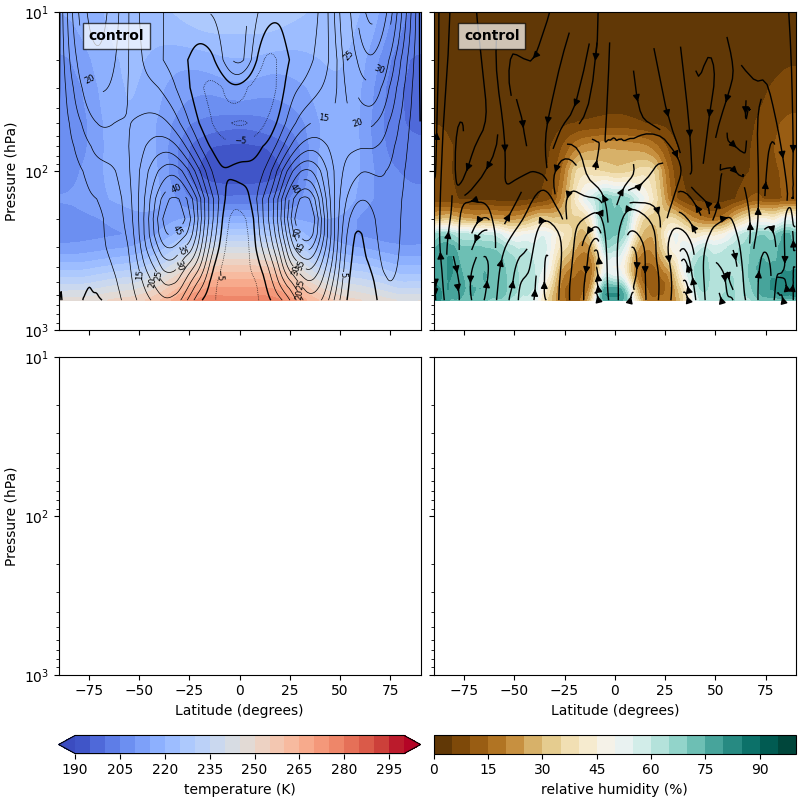

In [18]:
fig, ax = plt.subplots(2, 2, figsize=(8, 8), sharey=True, constrained_layout=True)

for i, ds in enumerate(dss[:1]):
    T_im, _, _, _ = plot_Tu_latpres(ax[i, 0], ds.latitude.values, p_test, Tbar, ubar)
    rh_im, _ = plot_rhv_latpres(ax[i, 1], ds.latitude.values, p_test, rhbar, vbar, omgbar)
    
    ax[i, 0].annotate(sim_names[i], (-75, 15), fontweight='bold', bbox=dict(facecolor='w', alpha=0.7))
    ax[i, 1].annotate(sim_names[i], (-75, 15), fontweight='bold', bbox=dict(facecolor='w', alpha=0.7))

    #ax[i, 0].plot(ds.latitude.values, CPTs[i][1]/100., color='k', lw=1, ls=':')
    #ax[i, 1].plot(ds.latitude.values, CPTs[i][1]/100., color='k', lw=1, ls=':')

ax[0, 0].set_xticklabels([])
ax[0, 1].set_xticklabels([])

ax[1, 0].set_xlabel("Latitude (degrees)")
ax[1, 1].set_xlabel("Latitude (degrees)")
    
for i in range(ax.shape[0]):
    ax[i, 0].set_ylabel("Pressure (hPa)")
    
ax[0, 0].invert_yaxis()
ax[0, 0].set_yscale('log')
    
for a in ax.ravel():
    a.set_xlim(-90, 90)
    a.set_ylim(1000, 10)
    
fig.colorbar(T_im, ax=ax[-1, 0], location='bottom', label="temperature (K)")
fig.colorbar(rh_im, ax=ax[-1, 1], location='bottom', label="relative humidity (%)")

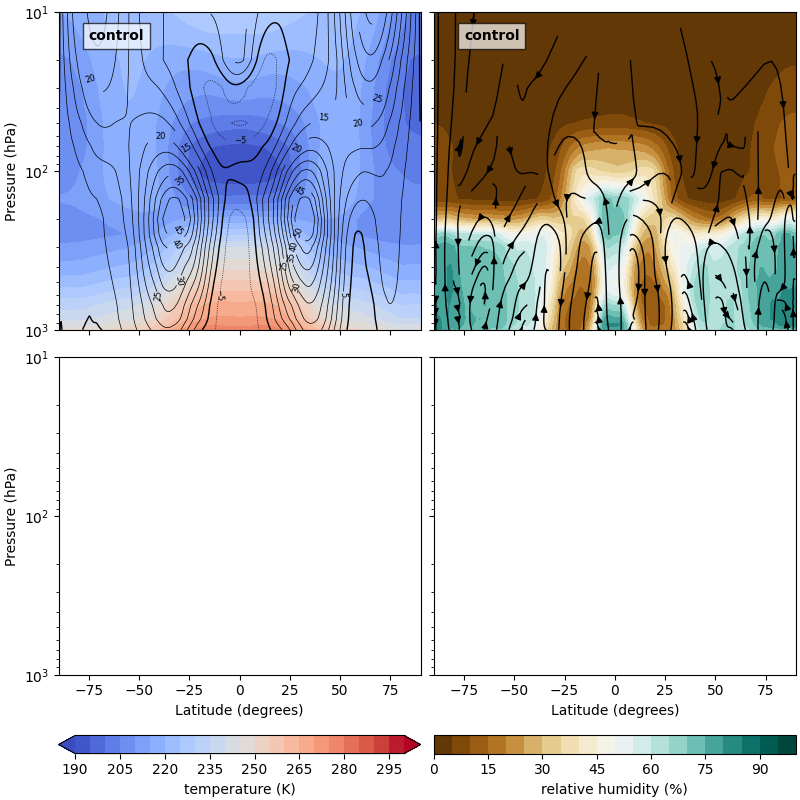

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(8, 8), sharey=True, constrained_layout=True)

for i, ds in enumerate(dss[:1]):
    ubar = ds.uzonal_isobaric.mean(dim=('longitude', 'Time')).values
    vbar = ds.umeridional_isobaric.mean(dim=('longitude', 'Time')).values
    omgbar = ds.omg_isobaric.mean(dim=('longitude', 'Time')).values
    rhbar = ds.rh_isobaric.mean(dim=('longitude', 'Time')).values
    Tbar = ds.t_isobaric.mean(dim=('longitude', 'Time')).values
    
    T_im, _, _, _ = plot_Tu_latpres(ax[i, 0], ds.latitude.values, ds.pres.values, Tbar, ubar)
    rh_im, _ = plot_rhv_latpres(ax[i, 1], ds.latitude.values, ds.pres.values, rhbar, vbar, omgbar)
    
    ax[i, 0].annotate(sim_names[i], (-75, 15), fontweight='bold', bbox=dict(facecolor='w', alpha=0.7))
    ax[i, 1].annotate(sim_names[i], (-75, 15), fontweight='bold', bbox=dict(facecolor='w', alpha=0.7))

    #ax[i, 0].plot(ds.latitude.values, CPTs[i][1]/100., color='k', lw=1, ls=':')
    #ax[i, 1].plot(ds.latitude.values, CPTs[i][1]/100., color='k', lw=1, ls=':')

ax[0, 0].set_xticklabels([])
ax[0, 1].set_xticklabels([])

ax[1, 0].set_xlabel("Latitude (degrees)")
ax[1, 1].set_xlabel("Latitude (degrees)")
    
for i in range(ax.shape[0]):
    ax[i, 0].set_ylabel("Pressure (hPa)")
    
ax[0, 0].invert_yaxis()
ax[0, 0].set_yscale('log')
    
for a in ax.ravel():
    a.set_xlim(-90, 90)
    a.set_ylim(1000, 10)
    
fig.colorbar(T_im, ax=ax[-1, 0], location='bottom', label="temperature (K)")
fig.colorbar(rh_im, ax=ax[-1, 1], location='bottom', label="relative humidity (%)")

if save: save_fig(fig, save_loc+'comp_temp_relhum.png', dpi=300)

In [ ]:
# Meridional eddy fluxes

fig, ax = plt.subplots(4, 2, figsize=(8, 8), constrained_layout='True')

for i, ds in enumerate(dss):
    ua = ds.uzonal_isobaric.sel(pres=[250, 700]) - ds.uzonal_isobaric.sel(pres=[250, 700]).mean(dim=('longitude', 'Time'))
    va = ds.umeridional_isobaric.sel(pres=[250, 700]) - ds.umeridional_isobaric.sel(pres=[250, 700]).mean(dim=('longitude', 'Time')) 
    Ta = ds.t_isobaric.sel(pres=[250, 700]) - ds.umeridional_isobaric.sel(pres=[250, 700]).mean(dim=('longitude', 'Time'))
    qva = ds.qv_isobaric.sel(pres=[250, 700]) - ds.qv_isobaric.sel(pres=[250, 700]).mean(dim=('longitude', 'Time'))
    
    eke = (ua*ua + va*va).mean(dim=('longitude', 'Time'))
    memf = (ua*va).mean(dim=('longitude', 'Time'))
    mehf = (va*Ta).mean(dim=('longitude', 'Time'))
    mewvf = (va*qva).mean(dim=('longitude', 'Time'))

    for j, var in enumerate([eke, memf, mehf, mewvf]):
        if j == 0:
            ax[j, 0].plot(ds.latitude.values, var[0], color=cols[i], label=sim_names[i])
        else:
            ax[j, 0].plot(ds.latitude.values, var[0], color=cols[i])
        ax[j, 1].plot(ds.latitude.values, var[1], color=cols[i])

for a in ax.ravel():
    a.set_xlim(-90, 90)

ax[0, 0].set_ylabel("Eddy kinetic \n energy (m$^2$ s$^{-2}$)")
ax[1, 0].set_ylabel("Meridional eddy \n momentum flux (m$^2$ s$^{-2}$)")
ax[2, 0].set_ylabel("Meridional heat \n flux (K m s$^{-1}$)")
ax[3, 0].set_ylabel("Meridional wv \n flux (g kg$^{-1}$ m s$^{-1}$)")

fig.legend(loc='outside lower center', ncol=4)
        
if save: save_fig(fig, save_loc+'comp_eddy_fluxes.png', dpi=300)

In [ ]:
imerg_ds = xr.open_mfdataset(list(sorted(glob.glob('/data/phh1-hosted/cwp29/imerg/*3IMERG.*.nc4')))[:100], concat_dim='time', combine='nested')

imerg_pr = imerg_ds.precipitation.coarsen(lat=10).mean().coarsen(lon=10).mean()

In [ ]:
# Normalised rainfall intensity distribution
from scipy.ndimage import uniform_filter1d

fig, ax = plt.subplots(1, 3, figsize=(8, 3), constrained_layout=True, sharey=True)

h, bins = np.histogram(imerg_pr, bins=300, range=(0, 300))
h = uniform_filter1d(h, size=10)
ax[0].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color='k', ls=':', label='IMERG (Obs)')
ax[0].set_yscale('log')

for s, ds in enumerate(dss):
    precip_con = ds.rainc + ds.i_rainc*100.
    precip_res = ds.rainnc + ds.i_rainnc*100.
    precip = precip_con + precip_res
    
    for i, precip_var in enumerate([precip, precip_con, precip_res]):
        if time_format == 'int':
            precip_rate = precip_var.diff("Time") / (dt / 24.0)
        else:
            dt_days = (
                precip_var.Time.diff("Time") / np.timedelta64(1, "D")
            )
            precip_rate = precip_var.diff("Time") / dt_days
        h, bins = np.histogram(precip_rate.values, bins=300, range=(0, 300))
        h = uniform_filter1d(h, size=10)
        if i == 0:
            ax[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color=cols[s], label=sim_names[s])
        else:
            ax[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color=cols[s])
        ax[i].set_yscale('log')

fig.legend(loc='outside lower center', ncol=5)

for a in ax:
    a.set_xlim(0, 300)
    a.set_ylim(1e-7, 1)
    a.set_xlabel("Rainfall rate (mm/day)")

ax[0].set_title("Total")
ax[0].set_ylabel("Normalised frequency")
ax[1].set_title("Parameterised")
ax[2].set_title("Resolved")
    
if save: save_fig(fig, save_loc+'comp_pr_dist.png', dpi=300)

In [ ]:
def calculate_rain_durations(pr_var, thresh):
    pr_thresh = np.where(pr_var > thresh, 1, 0)
    
    durations = []

    for i in range(pr_thresh.shape[1]):
        for j in range(pr_thresh.shape[2]):
            timeseries = pr_thresh[:, i, j]
    
            count = 0
            for k in range(pr_thresh.shape[0]):
                if timeseries[k] > 0:
                    count += 1
                else:
                    if count > 0:
                        durations.append(count)
                        count = 0
                        
    return durations
                    
fig, ax = plt.subplots(1, 3, figsize=(8, 3), constrained_layout=True, sharey=True)

h, bins = np.histogram(calculate_rain_durations(imerg_pr, 5), bins=39, range=(1, 40))
h = uniform_filter1d(h, size=5)
ax[0].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color='k', ls=':', label='IMERG (Obs)')
ax[0].set_yscale('log')

for s, ds in enumerate(dss):
    precip_con = ds.rainc + ds.i_rainc*100.
    precip_res = ds.rainnc + ds.i_rainnc*100.
    precip = precip_con + precip_res

    for i, precip_var in enumerate([precip, precip_con, precip_res]):
        if time_format == 'int':
            precip_rate = precip_var.diff("Time") / (dt / 24.0)
        else:
            dt_days = (
                precip_var.Time.diff("Time") / np.timedelta64(1, "D")
            )
            precip_rate = precip_var.diff("Time") / dt_days
        h, bins = np.histogram(calculate_rain_durations(precip_rate.values, 5), bins=39, range=(1, 40))
        h = uniform_filter1d(h, size=5)
        if i == 0:
            ax[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color=cols[s], label=sim_names[s])
        else:
            ax[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color=cols[s])
        ax[i].set_yscale('log')

for a in ax:
    a.set_xlim(1, 60)
    a.set_xlabel("Duration (days)")
    
fig.legend(loc='outside lower center', ncol=5)

ax[0].set_title("Total")
ax[0].set_ylabel("Normalised frequency")
ax[1].set_title("Parameterised")
ax[2].set_title("Resolved")

if save: save_fig(fig, save_loc+'comp_duration_dist.png', dpi=300)

In [ ]:
spec_levels = np.linspace(0, 2.5, 26)

fig, ax = plt.subplots(len(data_locs), 2, figsize=(8, 8), constrained_layout=True)

for d, ds in enumerate(dss):
    precip = ds.rainc + ds.i_rainc*100. + ds.rainnc + ds.i_rainnc*100.

    if time_format == 'int':
        precip_rate = precip.diff("Time") / (dt / 24.0)
    else:
        dt_days = (
            precip.Time.diff("Time") / np.timedelta64(1, "D")
        )
        precip_rate = precip.diff("Time") / dt_days
        
    pr = precip_rate.rename({'latitude':'lat', 'longitude':'lon'})
    pr = pr.load()
    print(pr)

    spd = 4
        
    raw_spectrum = spacetime_power(pr, lataggreg='mean', latitude_bounds=(-10, 10), dosymmetries=True, 
                                   segsize=int(32/spd), noverlap=int(16/spd), spd=spd)

    sym_smooth_spectrum = smooth_wavefreq(raw_spectrum.sel(component='symmetric'), freq_ax = 1)
    asym_smooth_spectrum = smooth_wavefreq(raw_spectrum.sel(component='antisymmetric'), freq_ax = 1)
    
    sym_sig_spectrum = raw_spectrum.sel(component='symmetric')/sym_smooth_spectrum
    asym_sig_spectrum = raw_spectrum.sel(component='antisymmetric')/asym_smooth_spectrum

    wn = sym_sig_spectrum.wavenumber
    f = sym_sig_spectrum.frequency

    sym_spec_im = ax[d, 0].contourf(wn, f, sym_sig_spectrum.T, levels=spec_levels, cmap='YlGnBu', extend='max')
    
    asym_spec_im = ax[d, 1].contourf(wn, f, asym_sig_spectrum.T, levels=spec_levels, cmap='YlGnBu', extend='max')
    
    freq, wavenum = genDispersionCurves()
    
    labels = ['MRG', 'IG', 'EIG', 'Kelvin', 'ER', 'IG']

    for i in range(3):
        for j in range(3):
            ax[d, 1].plot(wavenum[i, j], freq[i, j], color='r', alpha=0.5)
            ax[d, 0].plot(wavenum[i+3, j], freq[i+3, j], color='r', alpha=0.5)
    
    # Decorations
    for a in ax[d]:
        a.set_xlim(-15, 15)
        a.set_ylim(0, 0.5)
        
        if d == len(data_locs)-1:
            a.set_xlabel('Zonal wavenumber')
        else:
            a.set_xticklabels([])

    ax[d, 0].set_ylabel('Frequency (day$^{-1}$)')
    ax[d, 1].set_yticklabels([])
    
    ax[d, 0].axvline(0, color='k', ls='--')
    ax[d, 1].axvline(0, color='k', ls='--')
    
    ax[d, 0].annotate(sim_names[d], (-14, 0.45), fontweight='bold', bbox=dict(facecolor='w', alpha=0.7))

    if d == 0:
        ax[d, 0].annotate('ER', (-11, 0.12), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        ax[d, 0].annotate('Kelvin', (10, 0.4), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        ax[d, 0].annotate('IG', (-5, 0.4), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        
        ax[d, 1].annotate('MRG', (-12, 0.07), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        ax[d, 1].annotate('IG', (-5, 0.43), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))
        ax[d, 1].annotate('EIG', (11, 0.32), bbox=dict(facecolor='w', edgecolor='k', alpha=0.7))

ax[0, 0].set_title('Symmetric')
ax[0, 1].set_title('Anti-symmetric')

fig.colorbar(sym_spec_im, ax=ax[-1] ,location='bottom', shrink=0.5, label="Normalised power")

if save: save_fig(fig, save_loc+'comp_spectra.png', dpi=300)

In [ ]:
# Precip colourmap definition
precip_cols = [
    [255/255., 255/255., 255/255.], # white 
    [205/255., 236/255., 251/255.], # light blue 
    [157/255., 218/255., 247/255.], # blue
    [72/255., 142/255., 202/255.], # dark blue
    [72/255., 158/255., 148/255.], # light green
    [73/255., 181/255., 70/255.], # green
    [150/255., 203/255., 80/255.], # green-yellow
    [250/255., 232/255., 92/255.], # yellow
    [248/255., 184/255., 73/255.], # dark yellow
    [245/255., 106/255., 41/255.], # orange
    [230/255., 74/255., 41/255.], # dark orange
    [211/255., 31/255., 40/255.], # red
    [183/255., 27/255., 34/255.], # darker red
    [146/255., 21/255., 25/255.], #dark red
    [110/255., 15/255., 15/255.], #dark red
]

levels = np.linspace(0.01, 25, len(precip_cols))

precip_cmap = colors.LinearSegmentedColormap.from_list(name = "precip_rate", colors=precip_cols, N=len(precip_cols))
precip_norm = colors.BoundaryNorm(boundaries=levels, ncolors=len(precip_cols)-1)

In [ ]:
# Hovmoller diagrams of daily precipitation rate
    
fig, ax = plt.subplots(1, len(dss), figsize=(8, 3), constrained_layout=True)

for d, ds in enumerate(dss):
    precip = ds.rainc + ds.i_rainc*100. + ds.rainnc + ds.i_rainnc*100.
    precip = precip.sel(latitude=slice(-10, 10)).mean(dim='latitude')
    
    if time_format == 'int':
        pr = precip.diff("Time") / (dt / 24.0)
    else:
        dt_days = (
            precip.Time.diff("Time") / np.timedelta64(1, "D")
        )
        pr = precip.diff("Time") / dt_days
    
    hovmoller_im = ax[d].contourf(precip.longitude, pr.Time, pr.values, levels=levels, norm=precip_norm, cmap=precip_cmap, extend='max')

    ax[d].set_title(sim_names[d])
    
ax[0].set_ylabel("time (days)")
    
fig.colorbar(hovmoller_im, ax=ax[-1], location='right', label="Precipitation rate (mm/h)")
    
for a in ax:
    a.set_xlabel("Longitude")

if save: save_fig(fig, save_loc+'comp_hovmoller.png', dpi=300)

In [ ]:
# Latitude-height section of zonal-mean cloud fraction

fig, ax = plt.subplots(len(dss), 1, figsize=(8, 3.5*len(dss)), constrained_layout=True, sharex=True)

if len(dss) == 1:
    ax = [ax]

for i, ds in enumerate(dss):
    cldfrac = ds.cldfrac.mean(dim=('Time', 'longitude'))

    zgrid = ds.zgrid.mean(dim='longitude')
    z = 0.5 * (zgrid.isel(nVertLevelsP1=slice(0, -1)).values +
               zgrid.isel(nVertLevelsP1=slice(1, None)).values)

    lat = ds.latitude.values
    lat2d = np.broadcast_to(lat[None, :], cldfrac.shape)

    im = ax[i].contourf(lat2d, z / 1000.0, cldfrac.values, levels=np.linspace(0, 1, 21), cmap='binary', extend='max')
    ax[i].plot(ds.latitude.values, CPTs[i][0]/1000., color='k', lw=1, ls=':')
    ax[i].plot(ds.latitude.values, CPTs[i][0]/1000., color='k', lw=1, ls=':')
    
    ax[i].set_title(sim_names[i])
    ax[i].set_ylabel('Height (km)')
    ax[i].set_xlim(-90, 90)

ax[-1].set_xlabel('Latitude (degrees)')
fig.colorbar(im, ax=ax, location='right', label='Cloud fraction')

if save: save_fig(fig, save_loc+'comp_cldfrac_latheight.png', dpi=300)

In [ ]:
# Latitude-height section of zonal-mean vorticity

fig, ax = plt.subplots(len(dss), 1, figsize=(8, 3.5*len(dss)), constrained_layout=True, sharex=True)

if len(dss) == 1:
    ax = [ax]

for i, ds in enumerate(dss):
    if 'vorticity' in ds.data_vars:
        vort = ds.vorticity.mean(dim=('Time', 'longitude'))
    
        zgrid = ds.zgrid.mean(dim='longitude')
        z = 0.5 * (zgrid.isel(nVertLevelsP1=slice(0, -1)).values +
                   zgrid.isel(nVertLevelsP1=slice(1, None)).values)
    
        lat = ds.latitude.values
        lat2d = np.broadcast_to(lat[None, :], vort.shape)
    
        vmax = np.nanmax(np.abs(vort.values))
        levels = np.linspace(-vmax, vmax, 21)
    
        im = ax[i].contourf(lat2d, z/1000., vort.values, levels=levels, cmap='coolwarm', extend='both')
        ax[i].plot(ds.latitude.values, CPTs[i][0]/1000., color='k', lw=1, ls=':')
        ax[i].plot(ds.latitude.values, CPTs[i][0]/1000., color='k', lw=1, ls=':')
        
        ax[i].set_title(sim_names[i])
        ax[i].set_ylabel('Height (km)')
        ax[i].set_xlim(-90, 90)

ax[-1].set_xlabel('Latitude (degrees)')
fig.colorbar(im, ax=ax, location='right', label='Vorticity')

if save: save_fig(fig, save_loc+'comp_vorticity_latheight.png', dpi=300)

In [ ]:
# Histogram of OLR and time-mean lat/lon maps

fig, ax = plt.subplots(len(dss), 2, figsize=(10, 3.5*len(dss)), constrained_layout=True)

if len(dss) == 1:
    ax = [ax]

cols = ['b', 'r']
bins = np.linspace(100, 350, 80)

for i, ds in enumerate(dss):
    olr = ds.olrtoa
    olr_mean = olr.mean(dim='Time')

    h, b = np.histogram(olr.values.ravel(), bins=bins)
    ax[i, 0].plot(0.5 * (b[1:] + b[:-1]), h / h.sum(), color=cols[i])
    ax[i, 0].set_title(sim_names[i])
    ax[i, 0].set_xlabel(r'OLR (W m$^{-2}$)')
    ax[i, 0].set_ylabel('Normalised frequency')

    im = ax[i, 1].contourf(
        ds.longitude.values,
        ds.latitude.values,
        olr_mean.values,
        levels = np.linspace(200, 300, 151),
        norm=colors.PowerNorm(gamma=0.5), cmap='Blues',
        extend='both'
    )
    ax[i, 1].set_title(sim_names[i])
    ax[i, 1].set_xlabel('Longitude')
    ax[i, 1].set_ylabel('Latitude')

fig.colorbar(im, ax=ax[:, 1], location='right', label=r'OLR (W m$^{-2}$)')

if save: save_fig(fig, save_loc+'comp_olrtoa_hist_maps.png', dpi=300)

In [ ]:
# Latitude-height section of zonal-mean kinetic energy

fig, ax = plt.subplots(len(dss), 1, figsize=(8, 3.5*len(dss)), constrained_layout=True, sharex=True)

if len(dss) == 1:
    ax = [ax]

for i, ds in enumerate(dss):
    if 'ke' in ds.data_vars:
        ke = ds.ke.mean(dim=('Time', 'longitude')).transpose('nVertLevels', 'latitude')
    
        zgrid = ds.zgrid.mean(dim='longitude')
        z = 0.5 * (zgrid.isel(nVertLevelsP1=slice(0, -1)).values +
                   zgrid.isel(nVertLevelsP1=slice(1, None)).values)
    
        lat = ds.latitude.values
        lat2d = np.broadcast_to(lat[None, :], ke.shape)
    
        im = ax[i].contourf(lat2d, z/1000., ke.values, levels=np.linspace(0, np.nanmax(ke.values), 21), cmap='YlGnBu', extend='max')
        ax[i].plot(ds.latitude.values, CPTs[i][0]/1000., color='k', lw=1, ls=':')
        ax[i].plot(ds.latitude.values, CPTs[i][0]/1000., color='k', lw=1, ls=':')
        ax[i].set_title(sim_names[i])
        ax[i].set_ylabel('Height (km)')
        ax[i].set_xlim(-90, 90)

ax[-1].set_xlabel('Latitude (degrees)')
fig.colorbar(im, ax=ax, location='right', label=r'Kinetic energy (m$^2$ s$^{-2}$)')

if save: save_fig(fig, save_loc+'comp_ke_latheight.png', dpi=300)